# CDH17 expression: exploratory data analysis

This notebook describes the Phase 3 sample-level dataset and produces descriptive summaries and three exploratory figures. It does not perform hypothesis tests, batch correction, or biological/clinical efficacy interpretation.

## Data, scale, and reproducibility

The input is the targeted UCSC Xena Toil expression extraction with matching TCGA/GTEx phenotype annotations. Values are used in the dataset's reported scale, **log2(TPM + 0.001)**. This is not converted to log2(TPM + 1).

Run all cells from the project directory, or set the environment variable CDH17_PROJECT_ROOT to the project root. The setup cell also searches the current directory and its parents for the input CSV. Outputs are written under the project root in results/ and figures/.

In [9]:
from pathlib import Path
import os
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Find the project root without depending on the notebook's working directory.
candidates = []
root_override = os.environ.get("CDH17_PROJECT_ROOT")
if root_override:
    candidates.append(Path(root_override).expanduser().resolve())
cwd = Path.cwd().resolve()
candidates.extend([cwd, *cwd.parents])
PROJECT_ROOT = next(
    (candidate for candidate in candidates
     if (candidate / "data" / "cdh17_expression_annotated.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate data/cdh17_expression_annotated.csv. "
        "Run from the project directory or set CDH17_PROJECT_ROOT."
    )

DATA_PATH = PROJECT_ROOT / "data" / "cdh17_expression_annotated.csv"
PROVENANCE_PATH = PROJECT_ROOT / "data" / "data_provenance.md"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)
print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {DATA_PATH}")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("\nActual input columns and inferred pandas dtypes:")
display(pd.DataFrame({
    "column": df.columns,
    "dtype": [str(dtype) for dtype in df.dtypes],
    "missing_rows": [int(df[column].isna().sum()) for column in df.columns],
}))
print("\nObserved analysis groups and counts:")
display(df["analysis_group"].value_counts(dropna=False).rename_axis("analysis_group").to_frame("sample_count"))

Project root: /home/user/P00_Final_Project/CDH17_Analysis
Input: /home/user/P00_Final_Project/CDH17_Analysis/data/cdh17_expression_annotated.csv
Dataset shape: 7,860 rows × 14 columns

Actual input columns and inferred pandas dtypes:


,column,dtype,missing_rows
0,sampleID,str,0
1,CDH17_expression_log2_TPM_plus_0.001,float64,0
2,CDH17_expression_api_value,float64,0
3,_study,str,0
4,_primary_site,str,4
5,_sample_type,str,0
6,detailed_category,str,0
7,primary disease or tissue,str,0
8,_gender,str,3
9,analysis_group,str,0



Observed analysis groups and counts:


,sample_count
analysis_group,
Other GTEx normal tissues,7121
GTEx normal colon,308
TCGA colon primary tumors,288
TCGA rectum primary tumors,92
TCGA colon solid-tissue normals,41
TCGA rectum solid-tissue normals,10


## Validate the observed schema and labels

The prior cell prints the CSV's actual columns and inferred types before this cell refers to fields. The checks below verify the expected expression field, sample key, source annotations, all six group labels, unique sample IDs, and the expression scale documented in the provenance file.

In [10]:
SAMPLE_COL = "sampleID"
EXPR_COL = "CDH17_expression_log2_TPM_plus_0.001"
RAW_EXPR_COL = "CDH17_expression_api_value"
GROUP_COL = "analysis_group"
TISSUE_COL = "anatomical_tissue_label"
GROUP_ORDER = [
    "TCGA colon primary tumors",
    "TCGA rectum primary tumors",
    "TCGA colon solid-tissue normals",
    "TCGA rectum solid-tissue normals",
    "GTEx normal colon",
    "Other GTEx normal tissues",
]
REQUIRED_COLUMNS = {
    SAMPLE_COL, EXPR_COL, RAW_EXPR_COL, GROUP_COL, TISSUE_COL,
    "_study", "_primary_site", "_sample_type", "detailed_category",
    "primary disease or tissue", "_gender",
}
missing_columns = sorted(REQUIRED_COLUMNS.difference(df.columns))
if missing_columns:
    raise ValueError(f"Required columns absent from the observed CSV: {missing_columns}")

observed_groups = set(df[GROUP_COL].dropna().unique())
if observed_groups != set(GROUP_ORDER):
    raise ValueError(
        f"Unexpected analysis_group labels. Observed={sorted(observed_groups)}; "
        f"expected={GROUP_ORDER}"
    )
if df[SAMPLE_COL].isna().any() or df[SAMPLE_COL].duplicated().any():
    raise ValueError("sampleID has missing or duplicate values.")

provenance_text = PROVENANCE_PATH.read_text(encoding="utf-8")
scale_is_documented = re.search(
    r"log2\s*\(\s*TPM\s*\+\s*0\.001\s*\)", provenance_text, flags=re.IGNORECASE
) is not None
if not scale_is_documented:
    raise ValueError(
        "Could not verify log2(TPM + 0.001) in data/data_provenance.md; "
        "inspect the source scale before continuing."
    )

# Compare the saved expression column with the API-value copy without changing either.
expression_numeric = pd.to_numeric(df[EXPR_COL], errors="coerce")
api_value_numeric = pd.to_numeric(df[RAW_EXPR_COL], errors="coerce")
expression_missing = df[EXPR_COL].isna()
expression_nonnumeric = df[EXPR_COL].notna() & expression_numeric.isna()
api_copy_disagreement = (
    expression_numeric.notna()
    & api_value_numeric.notna()
    & ~np.isclose(expression_numeric, api_value_numeric, rtol=0, atol=0)
)
if api_copy_disagreement.any():
    raise ValueError("The expression column differs from its saved API-value copy.")

group_counts = (
    df[GROUP_COL].value_counts().reindex(GROUP_ORDER, fill_value=0).astype(int)
)
print("Validated expression field:", EXPR_COL)
print("Scale from provenance: log2(TPM + 0.001)")
print("Observed groups:")
display(group_counts.rename_axis("analysis_group").to_frame("sample_count"))
print(f"Missing expression values: {int(expression_missing.sum())}")
print(f"Nonnumeric nonmissing expression values: {int(expression_nonnumeric.sum())}")
print(f"Expression/API-copy disagreements: {int(api_copy_disagreement.sum())}")
print("Auxiliary column missingness:")
display(df.isna().sum().rename("missing_rows").to_frame().query("missing_rows > 0"))

Validated expression field: CDH17_expression_log2_TPM_plus_0.001
Scale from provenance: log2(TPM + 0.001)
Observed groups:


,sample_count
analysis_group,
TCGA colon primary tumors,288
TCGA rectum primary tumors,92
TCGA colon solid-tissue normals,41
TCGA rectum solid-tissue normals,10
GTEx normal colon,308
Other GTEx normal tissues,7121


Missing expression values: 0
Nonnumeric nonmissing expression values: 0
Expression/API-copy disagreements: 0
Auxiliary column missingness:


,missing_rows
_primary_site,4
_gender,3
exclusion_reason,7860


## Descriptive statistics

For each analysis group, report total sample count, usable numeric count, mean, median, sample standard deviation, 25th and 75th percentiles, minimum, maximum, missingness, and nonnumeric values. Missing or invalid values are counted, never imputed. No inferential tests are run.

In [11]:
stats_rows = []
for group in GROUP_ORDER:
    mask = df[GROUP_COL].eq(group)
    values = expression_numeric.loc[mask].dropna()
    n_total = int(mask.sum())
    n_missing_source = int(expression_missing.loc[mask].sum())
    n_nonnumeric = int(expression_nonnumeric.loc[mask].sum())
    row = {
        "analysis_group": group,
        "sample_count": n_total,
        "numeric_expression_count": int(values.size),
        "missing_expression_count": n_missing_source + n_nonnumeric,
        "missingness_percent": 100 * (n_missing_source + n_nonnumeric) / n_total if n_total else np.nan,
        "nonnumeric_expression_count": n_nonnumeric,
        "mean": values.mean() if len(values) else np.nan,
        "median": values.median() if len(values) else np.nan,
        "standard_deviation": values.std(ddof=1) if len(values) > 1 else np.nan,
        "percentile_25": values.quantile(0.25) if len(values) else np.nan,
        "percentile_75": values.quantile(0.75) if len(values) else np.nan,
        "minimum": values.min() if len(values) else np.nan,
        "maximum": values.max() if len(values) else np.nan,
    }
    stats_rows.append(row)

eda_summary = pd.DataFrame(stats_rows)
summary_path = RESULTS_DIR / "eda_summary.csv"
eda_summary.to_csv(summary_path, index=False)
display(eda_summary.round(4))
print(f"Saved descriptive statistics: {summary_path}")

,analysis_group,sample_count,numeric_expression_count,missing_expression_count,missingness_percent,nonnumeric_expression_count,mean,median,standard_deviation,percentile_25,percentile_75,minimum,maximum
0,TCGA colon primary tumors,288,288,0,0.0,0,7.2785,7.4535,1.2001,6.9165,7.9782,-0.394,9.469
1,TCGA rectum primary tumors,92,92,0,0.0,0,7.5577,7.6750,0.7332,7.2170,7.9890,5.171,9.059
2,TCGA colon solid-tissue normals,41,41,0,0.0,0,8.1236,8.2430,0.6365,7.9350,8.4110,5.390,8.955
3,TCGA rectum solid-tissue normals,10,10,0,0.0,0,7.8909,7.9195,0.7089,7.5002,8.2770,6.870,8.958
4,GTEx normal colon,308,308,0,0.0,0,2.6072,1.4200,4.1389,-1.2830,7.1482,-6.506,9.302
5,Other GTEx normal tissues,7121,7121,0,0.0,0,-4.9133,-4.2930,3.1606,-6.5060,-2.9320,-9.966,8.047


Saved descriptive statistics: /home/user/P00_Final_Project/CDH17_Analysis/results/eda_summary.csv


## Distribution and annotation diagnostics

These checks describe observed extremes, potential lower-bound concentration under the reported transformation, within-group concentration, and label consistency. Tukey-fence counts are descriptive flags only; they are not hypothesis tests and do not establish erroneous observations.

In [12]:
valid_expression = expression_numeric.dropna()
reported_floor = float(np.log2(0.001))
observed_minimum = float(valid_expression.min())
floor_tolerance = 0.002  # accommodates the source values' displayed decimal precision
floor_mask = (valid_expression - reported_floor).abs() <= floor_tolerance

# Pooled fences are shown as a coarse description only; source and tissue groups differ.
q1, q3 = valid_expression.quantile([0.25, 0.75])
pooled_iqr = q3 - q1
pooled_low_fence = q1 - 1.5 * pooled_iqr
pooled_high_fence = q3 + 1.5 * pooled_iqr
pooled_tukey_flags = (valid_expression < pooled_low_fence) | (valid_expression > pooled_high_fence)

diagnostic_rows = []
for group in GROUP_ORDER:
    values = expression_numeric.loc[df[GROUP_COL].eq(group)].dropna()
    if len(values):
        gq1, gq3 = values.quantile([0.25, 0.75])
        giqr = gq3 - gq1
        mode_share = float(values.value_counts(normalize=True).iloc[0])
        near_floor = int(((values - reported_floor).abs() <= floor_tolerance).sum())
        high_fence = gq3 + 1.5 * giqr
        low_fence = gq1 - 1.5 * giqr
        tukey_count = int(((values < low_fence) | (values > high_fence)).sum())
        diagnostic_rows.append({
            "analysis_group": group,
            "n": int(len(values)),
            "unique_expression_values": int(values.nunique()),
            "most_common_value_share": mode_share,
            "iqr": float(giqr),
            "near_reported_floor_count": near_floor,
            "group_tukey_fence_flag_count": tukey_count,
            "minimum": float(values.min()),
            "maximum": float(values.max()),
        })

diagnostics = pd.DataFrame(diagnostic_rows)
print(f"Observed overall minimum: {observed_minimum:.3f}")
print(f"Theoretical log2(0.001) lower bound: {reported_floor:.6f}")
print(f"Values within {floor_tolerance} of that bound: {int(floor_mask.sum())} / {len(valid_expression)}")
print(f"Values equal to the observed minimum: {int(valid_expression.eq(observed_minimum).sum())}")
print(
    f"Pooled 1.5×IQR descriptive flags: {int(pooled_tukey_flags.sum())} "
    f"(fences {pooled_low_fence:.3f} to {pooled_high_fence:.3f})"
)
display(diagnostics.round(4))

# Verify that the derived anatomical label matches the source detail field or fallback.
detail = df["detailed_category"].fillna("").astype(str).str.strip()
fallback = df["primary disease or tissue"].fillna("").astype(str).str.strip()
expected_anatomical_label = detail.where(detail.ne(""), fallback)
stored_anatomical_label = df[TISSUE_COL].fillna("").astype(str).str.strip()
label_mismatch = expected_anatomical_label.ne(stored_anatomical_label)
missing_broad_site = df["_primary_site"].isna() | df["_primary_site"].astype(str).eq("")
gtex_missing_site = df["_study"].eq("GTEX") & missing_broad_site
print(f"Anatomical label mismatches against source fields: {int(label_mismatch.sum())}")
print(f"GTEx rows with missing broad site field: {int(gtex_missing_site.sum())}")
print("Those rows' detailed labels:")
display(df.loc[gtex_missing_site, [SAMPLE_COL, "_primary_site", "detailed_category", "primary disease or tissue", TISSUE_COL]])
print("GTEx colon subtype labels:")
display(
    df.loc[df[GROUP_COL].eq("GTEx normal colon"), "detailed_category"]
      .value_counts(dropna=False).rename_axis("detailed_category").to_frame("sample_count")
)

Observed overall minimum: -9.966
Theoretical log2(0.001) lower bound: -9.965784
Values within 0.002 of that bound: 1447 / 7860
Values equal to the observed minimum: 1447
Pooled 1.5×IQR descriptive flags: 640 (fences -12.683 to 3.789)


,analysis_group,n,unique_expression_values,most_common_value_share,iqr,near_reported_floor_count,group_tukey_fence_flag_count,minimum,maximum
0,TCGA colon primary tumors,288,275,0.0069,1.0618,0,13,-0.394,9.469
1,TCGA rectum primary tumors,92,89,0.0217,0.7720,0,4,5.171,9.059
2,TCGA colon solid-tissue normals,41,40,0.0488,0.4760,0,3,5.390,8.955
3,TCGA rectum solid-tissue normals,10,10,0.1000,0.7767,0,0,6.870,8.958
4,GTEx normal colon,308,239,0.0195,8.4312,0,0,-6.506,9.302
5,Other GTEx normal tissues,7121,230,0.2032,3.5740,1447,92,-9.966,8.047


Anatomical label mismatches against source fields: 0
GTEx rows with missing broad site field: 4
Those rows' detailed labels:


,sampleID,_primary_site,detailed_category,primary disease or tissue,anatomical_tissue_label
6361,GTEX-YEC3-1426-101806-SM-5PNXX,NaN,Stomach,Stomach,Stomach
6372,GTEX-YEC3-2526-101809-SM-5CVLT,NaN,Esophagus - Mucosa,Esophagus - Mucosa,Esophagus - Mucosa
6383,GTEX-YEC4-1026-101814-SM-5P9FX,NaN,Esophagus - Mucosa,Esophagus - Mucosa,Esophagus - Mucosa
6435,GTEX-YFC4-0126-101855-SM-5CVLZ,NaN,Skin - Sun Exposed (Lower Leg),Skin - Sun Exposed (Lower Leg),Skin - Sun Exposed (Lower Leg)


GTEx colon subtype labels:


,sample_count
detailed_category,
Colon - Transverse,167
Colon - Sigmoid,141


## Figure A — TCGA colorectal tumors and solid-tissue normals

The plot shows sample-level distributions for TCGA colon and rectum primary tumors and their corresponding solid-tissue-normal groups. It is descriptive; the points and boxes do not imply pairing between tumor and normal samples.

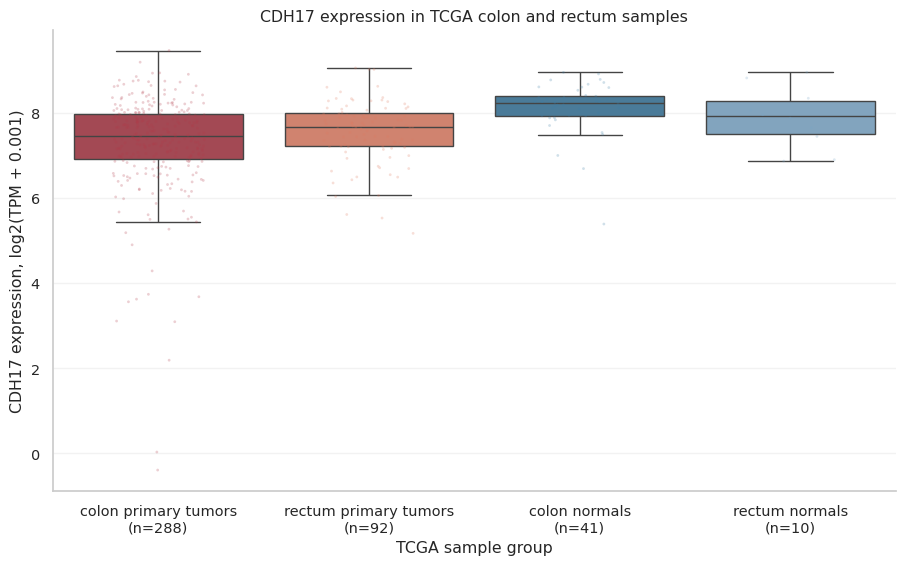

Saved: /home/user/P00_Final_Project/CDH17_Analysis/figures/figure_A_tcga_colorectal_distributions.png


In [13]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
palette = {
    "TCGA colon primary tumors": "#b23a48",
    "TCGA rectum primary tumors": "#e07a5f",
    "TCGA colon solid-tissue normals": "#3d7ea6",
    "TCGA rectum solid-tissue normals": "#78a6c8",
}
figure_a_groups = [
    "TCGA colon primary tumors",
    "TCGA rectum primary tumors",
    "TCGA colon solid-tissue normals",
    "TCGA rectum solid-tissue normals",
]
figure_a = df[df[GROUP_COL].isin(figure_a_groups)].copy()
figure_a["_expression_for_plot"] = expression_numeric.loc[figure_a.index]
fig, ax = plt.subplots(figsize=(9.2, 5.8))
sns.boxplot(
    data=figure_a, x=GROUP_COL, y="_expression_for_plot",
    order=figure_a_groups, hue=GROUP_COL, hue_order=figure_a_groups,
    palette=palette, dodge=False, showfliers=False, linewidth=1.0,
    legend=False, ax=ax,
)
sns.stripplot(
    data=figure_a, x=GROUP_COL, y="_expression_for_plot",
    order=figure_a_groups, hue=GROUP_COL, hue_order=figure_a_groups,
    palette=palette, dodge=False, jitter=0.22, alpha=0.24, size=2.0,
    linewidth=0, legend=False, ax=ax,
)
tick_labels = [
    f"{group.replace('TCGA ', '').replace(' tumors', ' tumors').replace(' solid-tissue normals', ' normals')}\n(n={int((figure_a[GROUP_COL] == group).sum()):,})"
    for group in figure_a_groups
]
ax.set_xticks(range(len(figure_a_groups)), labels=tick_labels)
ax.set_xlabel("TCGA sample group")
ax.set_ylabel("CDH17 expression, log2(TPM + 0.001)")
ax.set_title("CDH17 expression in TCGA colon and rectum samples")
ax.grid(axis="y", alpha=0.25)
sns.despine(ax=ax)
fig.tight_layout()
figure_a_path = FIGURES_DIR / "figure_A_tcga_colorectal_distributions.png"
fig.savefig(figure_a_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_a_path}")

## Figure B — TCGA colorectal primary tumors and GTEx normal colon

Tumor samples are sourced from TCGA (colon and rectum primary tumors); normal colon samples are sourced from GTEx. The source names are included in the x-axis labels because cohort/source differs between these groups.

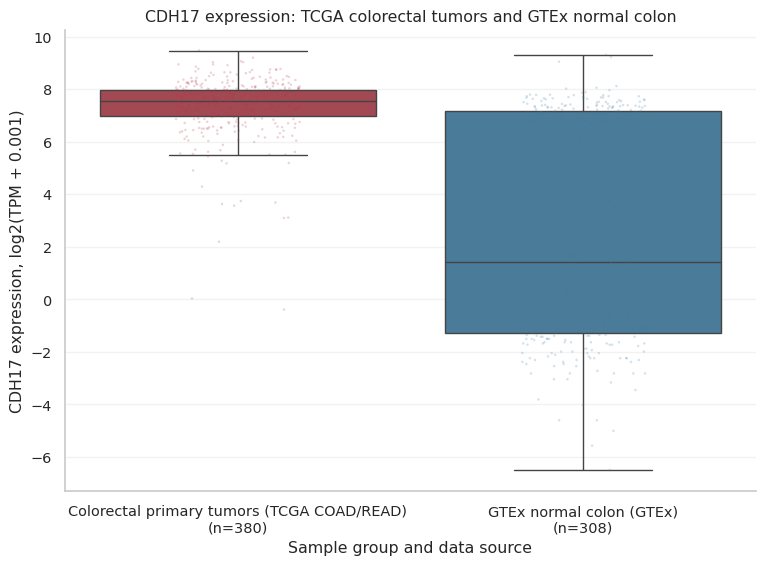

Saved: /home/user/P00_Final_Project/CDH17_Analysis/figures/figure_B_tcga_tumors_vs_gtex_colon.png


In [14]:
tcga_tumor_groups = {"TCGA colon primary tumors", "TCGA rectum primary tumors"}
figure_b = df[
    df[GROUP_COL].isin(tcga_tumor_groups | {"GTEx normal colon"})
].copy()
figure_b["comparison_group"] = np.where(
    figure_b[GROUP_COL].eq("GTEx normal colon"),
    "GTEx normal colon (GTEx)",
    "Colorectal primary tumors (TCGA COAD/READ)",
)
figure_b_order = [
    "Colorectal primary tumors (TCGA COAD/READ)",
    "GTEx normal colon (GTEx)",
]
figure_b_palette = {
    figure_b_order[0]: "#b23a48",
    figure_b_order[1]: "#3d7ea6",
}
figure_b["_expression_for_plot"] = expression_numeric.loc[figure_b.index]
fig, ax = plt.subplots(figsize=(7.8, 5.8))
sns.boxplot(
    data=figure_b, x="comparison_group", y="_expression_for_plot",
    order=figure_b_order, hue="comparison_group", hue_order=figure_b_order,
    palette=figure_b_palette, dodge=False, showfliers=False, linewidth=1.0,
    legend=False, ax=ax,
)
sns.stripplot(
    data=figure_b, x="comparison_group", y="_expression_for_plot",
    order=figure_b_order, hue="comparison_group", hue_order=figure_b_order,
    palette=figure_b_palette, dodge=False, jitter=0.18, alpha=0.22, size=1.8,
    linewidth=0, legend=False, ax=ax,
)
counts_b = figure_b["comparison_group"].value_counts()
ax.set_xticks(
    range(len(figure_b_order)),
    labels=[f"{group}\n(n={int(counts_b.get(group, 0)):,})" for group in figure_b_order],
)
ax.set_xlabel("Sample group and data source")
ax.set_ylabel("CDH17 expression, log2(TPM + 0.001)")
ax.set_title("CDH17 expression: TCGA colorectal tumors and GTEx normal colon")
ax.grid(axis="y", alpha=0.25)
sns.despine(ax=ax)
fig.tight_layout()
figure_b_path = FIGURES_DIR / "figure_B_tcga_tumors_vs_gtex_colon.png"
fig.savefig(figure_b_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_b_path}")

## Figure C — GTEx normal tissues by detailed anatomical label

The horizontal boxplots retain the detailed GTEx tissue labels. Labels are ordered from lower to higher observed median expression to make the full set easier to scan; this ordering is descriptive and does not imply a statistical ranking.

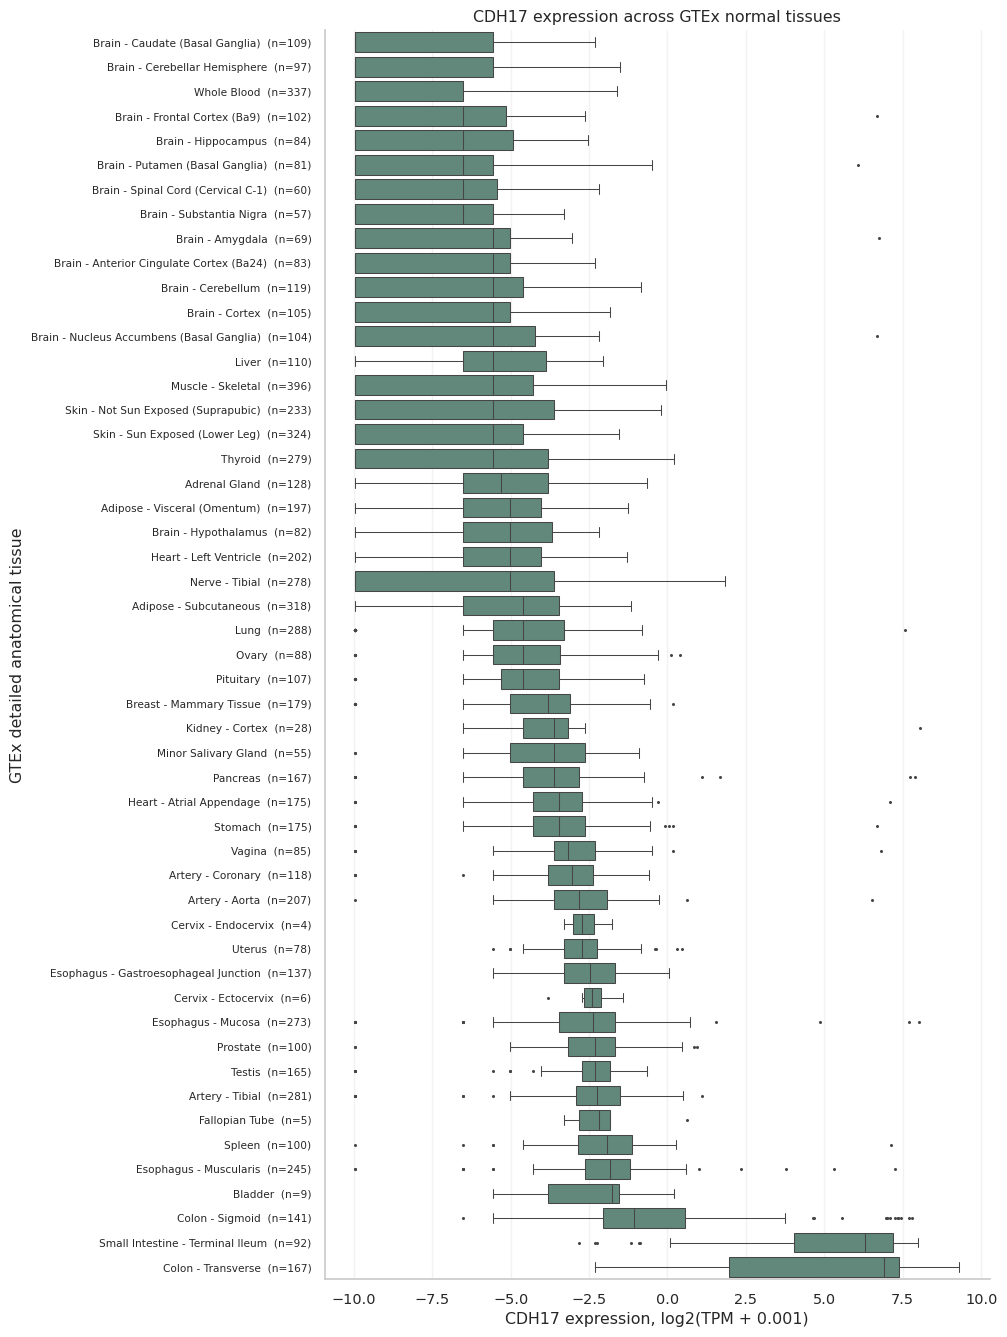

GTEx normal tissue labels plotted: 51
Saved: /home/user/P00_Final_Project/CDH17_Analysis/figures/figure_C_gtex_normal_tissues.png


In [15]:
gtex_normal = df[
    df["_study"].eq("GTEX") & df["_sample_type"].eq("Normal Tissue")
].copy()
gtex_normal["_expression_for_plot"] = expression_numeric.loc[gtex_normal.index]
if gtex_normal[TISSUE_COL].isna().any() or gtex_normal[TISSUE_COL].astype(str).str.strip().eq("").any():
    raise ValueError("GTEx normal tissue rows include missing detailed anatomical labels.")

tissue_order = (
    gtex_normal.groupby(TISSUE_COL)["_expression_for_plot"]
    .median().sort_values(kind="stable").index.tolist()
)
tissue_counts = gtex_normal[TISSUE_COL].value_counts()
tissue_tick_labels = [
    f"{tissue}  (n={int(tissue_counts[tissue]):,})" for tissue in tissue_order
]
fig_height = max(10.5, 0.265 * len(tissue_order))
fig, ax = plt.subplots(figsize=(10.2, fig_height))
sns.boxplot(
    data=gtex_normal, x="_expression_for_plot", y=TISSUE_COL,
    order=tissue_order, color="#5b8e7d", showfliers=True,
    fliersize=1.2, linewidth=0.75, ax=ax,
)
ax.set_yticks(range(len(tissue_order)), labels=tissue_tick_labels)
ax.set_xlabel("CDH17 expression, log2(TPM + 0.001)")
ax.set_ylabel("GTEx detailed anatomical tissue")
ax.set_title("CDH17 expression across GTEx normal tissues")
ax.grid(axis="x", alpha=0.25)
ax.tick_params(axis="y", labelsize=7.6)
sns.despine(ax=ax)
fig.tight_layout()
figure_c_path = FIGURES_DIR / "figure_C_gtex_normal_tissues.png"
fig.savefig(figure_c_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"GTEx normal tissue labels plotted: {len(tissue_order)}")
print(f"Saved: {figure_c_path}")

## Saved outputs and interpretation limits

The final cell confirms the requested output files exist and prints the descriptive group medians. The analysis remains exploratory: source/cohort differences may affect the observed distributions, and RNA expression does not establish protein abundance, ADC efficacy, or clinical safety.

In [16]:
print("Group medians in the reported expression scale:")
display(
    eda_summary.set_index("analysis_group")[["sample_count", "median"]]
      .reindex(GROUP_ORDER).round(4)
)
output_paths = [summary_path, figure_a_path, figure_b_path, figure_c_path]
print("\nOutput files:")
for path in output_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Expected output was not created: {path}")
    print(f"{path.relative_to(PROJECT_ROOT)} — {path.stat().st_size:,} bytes")
print("\nNo hypothesis tests or batch correction were run.")

Group medians in the reported expression scale:


,sample_count,median
analysis_group,,
TCGA colon primary tumors,288,7.4535
TCGA rectum primary tumors,92,7.6750
TCGA colon solid-tissue normals,41,8.2430
TCGA rectum solid-tissue normals,10,7.9195
GTEx normal colon,308,1.4200
Other GTEx normal tissues,7121,-4.2930



Output files:
results/eda_summary.csv — 902 bytes
figures/figure_A_tcga_colorectal_distributions.png — 181,131 bytes
figures/figure_B_tcga_tumors_vs_gtex_colon.png — 203,716 bytes
figures/figure_C_gtex_normal_tissues.png — 623,830 bytes

No hypothesis tests or batch correction were run.
